# Fase 4 de CRISP-DM · Modelado y ajuste de hiperparámetros

Se comparan una regresión logística multinomial como línea base, una SVM con kernel RBF, un Random Forest y una red neuronal MLP de tres capas ocultas. La entrada de todos los modelos es el vector de 31 descriptores de la fase 3. La salida corresponde a una de las tres etiquetas de calidad del CSV, `Bad`, `Good` o `Mixed`.

Se usan únicamente los registros asignados a `train` y `val` en la preparación. Los hiperparámetros se seleccionan mediante validación cruzada agrupada dentro de `train`. Cada modelo seleccionado se reajusta con todo `train` y se compara en el `val` existente. La prueba final queda reservada para la fase 5.

`Mixed` identifica la procedencia de recortes de imágenes con calidades diversas. Las métricas miden concordancia con esta etiqueta. Evaluar una categoría «Regular» por ejemplar requiere anotaciones individuales.

In [1]:
import json
from pathlib import Path
import tempfile
import warnings

import joblib
from joblib import parallel_backend
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

DATA_FILE = Path("experiments/results/prepared_features_dataset.csv")
ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / DATA_FILE).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(f"No se encontró {DATA_FILE} en el repositorio")

SEED = 42
N_JOBS = 3
CLASSES = ["Bad", "Good", "Mixed"]
FEATURES = [
    "area_ratio", "d_norm", "bbox_width_norm", "bbox_height_norm", "bbox_aspect_ratio",
    "mean_R", "mean_G", "mean_B", "std_R", "std_G", "std_B",
    "mean_H", "mean_S", "mean_V", "std_H", "std_S", "std_V",
    "laplacian_var", "laplacian_abs_mean", "sobel_mean", "sobel_std",
    "dark_pixel_ratio", "necrotic_pixel_ratio",
] + [f"hue_bin_{index}" for index in range(8)]
METADATA = ["filename", "fruit", "quality", "is_custom_group", "split"]

reader = pd.read_csv(ROOT / DATA_FILE, usecols=FEATURES + METADATA, chunksize=4096)
with reader:
    data = pd.concat(
        (chunk.loc[chunk["split"].isin(("train", "val"))] for chunk in reader),
        ignore_index=True,
    )

if set(data["split"]) != {"train", "val"} or not data["is_custom_group"].eq(False).all():
    raise ValueError("Se esperaban los splits públicos train y val preparados en fase 3")
if data[METADATA].isna().any().any() or not np.isfinite(data[FEATURES].to_numpy()).all():
    raise ValueError("Los registros de modelado contienen metadatos o descriptores inválidos")
for split in ("train", "val"):
    if set(data.loc[data["split"].eq(split), "quality"]) != set(CLASSES):
        raise ValueError(f"Faltan clases de calidad en {split}")

train = data.loc[data["split"].eq("train")].reset_index(drop=True)
val = data.loc[data["split"].eq("val")].reset_index(drop=True)
X_train, y_train = train[FEATURES], train["quality"]
X_val, y_val = val[FEATURES], val["quality"]

print(f"{len(FEATURES)} descriptores; {len(train):,} ejemplos train y {len(val):,} ejemplos val.")
display(pd.crosstab(data["split"], data["quality"], margins=True))

31 descriptores; 10,974 ejemplos train y 2,352 ejemplos val.


quality,Bad,Good,Mixed,All
split,,,,
train,4719,4764,1491,10974
val,1011,1021,320,2352
All,5730,5785,1811,13326


## Protocolo y control de particiones

Se conserva la partición de fase 3. Para que la **búsqueda de hiperparámetros** evite separar recortes o variantes reconocibles, los folds se construyen solo en `train` con `StratifiedGroupKFold`. Se retira el sufijo de recorte al recuperar el nombre de origen. Las tomas con fecha en el nombre se agrupan por fruta cuando la separación temporal es de hasta 30 segundos. Las que carecen de fecha se agrupan de forma conservadora por fruta y carpeta de calidad. Un grupo de captura aproxima una sesión; la identidad física de los ejemplares requeriría anotación.

Se elige, entre 20 semillas reproducibles, la partición de tres folds con menor desviación cuadrática promedio en la proporción de cada clase asignada a cada fold respecto a $1/3$. Esta decisión usa solo los grupos y las etiquetas de entrenamiento. Los cuatro modelos usan los mismos folds.

Como `val` ya fue generado en la fase 3, se mide cuántas fotos identificables por nombre aparecen en las dos particiones. Se presenta el resultado de todo `val` y un análisis adicional sobre las filas de `val` cuyo origen identificado no aparece en `train`. Este segundo resultado todavía puede compartir sesiones o ejemplares fotografiados con nombres distintos.

In [2]:
def source_stems(frame):
    return (
        frame["filename"].str.casefold()
        .str.replace(r"\.[^.]+$", "", regex=True)
        .str.replace(r"_crop_\d+$", "", regex=True)
    )


def source_ids(frame):
    return frame["fruit"] + "/" + frame["quality"] + "/" + source_stems(frame)


def capture_groups(frame):
    stamp = source_stems(frame).str.extract(r"(20\d{6})_?(\d{6})(?!\d)")
    captured = pd.to_datetime(stamp[0] + stamp[1], format="%Y%m%d%H%M%S", errors="coerce")
    dated = frame[["fruit"]].assign(captured=captured).dropna()
    dated = dated.sort_values(["fruit", "captured"], kind="stable")
    gap = dated.groupby("fruit")["captured"].diff().dt.total_seconds()
    sessions = dated["fruit"] + "/" + (gap.isna() | gap.gt(30)).cumsum().astype(str)
    undated = "sin-fecha/" + frame["fruit"] + "/" + frame["quality"]
    return sessions.reindex(frame.index).fillna(undated)


def grouped_folds(features, labels, groups):
    folds_count = 3
    totals = labels.value_counts().reindex(CLASSES)
    candidates = []
    for seed in range(SEED, SEED + 20):
        splitter = StratifiedGroupKFold(n_splits=folds_count, shuffle=True, random_state=seed)
        folds = list(splitter.split(features, labels, groups))
        counts = pd.DataFrame([
            labels.iloc[held_out].value_counts().reindex(CLASSES, fill_value=0)
            for _, held_out in folds
        ])
        if counts.gt(0).all().all():
            imbalance = ((counts.div(totals) - 1 / folds_count) ** 2).to_numpy().mean()
            candidates.append((imbalance, seed, folds, counts))
    if not candidates:
        raise ValueError("No se encontraron tres folds de captura con todas las clases")
    _, seed, folds, counts = min(candidates, key=lambda item: item[0])
    return seed, folds, counts


train_sources, val_sources = source_ids(train), source_ids(val)
shared_sources = set(train_sources) & set(val_sources)
different_source = ~val_sources.isin(shared_sources)
if not different_source.any():
    raise ValueError("No hay ejemplos de validación con un origen identificable diferente")

groups = capture_groups(train)
cv_seed, folds, fold_counts = grouped_folds(X_train, y_train, groups)
for fit_indices, holdout_indices in folds:
    assert set(groups.iloc[fit_indices]).isdisjoint(groups.iloc[holdout_indices])
    assert set(train_sources.iloc[fit_indices]).isdisjoint(train_sources.iloc[holdout_indices])
    assert set(y_train.iloc[fit_indices]) == set(y_train.iloc[holdout_indices]) == set(CLASSES)

print(f"Grupos en train: {groups.nunique()}; semilla para los folds: {cv_seed}.")
print(f"Fotos de origen compartidas por train y val: {len(shared_sources)}.")
print(f"Filas de val con un origen compartido: {(~different_source).sum()}.")
display(fold_counts.set_axis(["Fold 1", "Fold 2", "Fold 3"]).rename_axis("Validación interna"))

Grupos en train: 203; semilla para los folds: 61.
Fotos de origen compartidas por train y val: 199.
Filas de val con un origen compartido: 225.


quality,Bad,Good,Mixed
Validación interna,,,
Fold 1,1293,1737,498
Fold 2,1877,1496,572
Fold 3,1549,1531,421


## Modelos y justificación matemática · PI3

Sea $x=\phi(I)\in\mathbb{R}^{31}$ el vector de la imagen y $y\in\{\mathrm{Bad},\mathrm{Good},\mathrm{Mixed}\}$ la etiqueta. Para regresión logística, SVM y MLP se aplica $z_j=(x_j-\mu_j)/\sigma_j$. Los momentos se estiman dentro de cada fold de ajuste mediante un `Pipeline`. El Random Forest usa los valores originales porque un umbral de un árbol depende del orden de los valores de la variable.

1. **Regresión logística multinomial.** Estima $p_k(z)=\exp(w_k^\top z+b_k)/\sum_j\exp(w_j^\top z+b_j)$ mediante pérdida de entropía cruzada con penalización $L_2$. Sus fronteras lineales ofrecen una referencia para medir lo que aportan los modelos no lineales. Se fija $C=1$.
2. **SVM RBF.** El kernel $K(z,z')=\exp(-\gamma\lVert z-z'\rVert_2^2)$ representa similitud entre descriptores y permite fronteras curvas. En cada problema binario la SVM busca minimizar $\tfrac12\lVert w\rVert^2+C\sum_i \max(0,1-y_if(z_i))$. Se ajustan $C$, que controla cuánto se penalizan las violaciones del margen, y $\gamma$, que determina el alcance de la similitud. La implementación combina clasificadores uno contra uno.
3. **Random Forest.** Combina árboles con muestras bootstrap y un subconjunto aleatorio de descriptores en cada división. La impureza de Gini de un nodo es $1-\sum_k p_k^2$. Promediar las probabilidades de los árboles facilita aprender interacciones de color, textura y forma. La profundidad máxima y el mínimo de muestras por hoja controlan la complejidad. Los pesos de clase se estiman en la muestra bootstrap de cada árbol.
4. **MLP de tres capas ocultas.** Cada capa aplica $h_\ell=\operatorname{ReLU}(W_\ell h_{\ell-1}+b_\ell)$. La salida softmax se ajusta con entropía cruzada y regularización $L_2$ sobre los pesos. Adam actualiza los parámetros por mini-lotes. Se comparan dos anchos de capas y dos valores de $\alpha$. El máximo es 100 épocas y la convergencia se controla con la pérdida de ajuste. Trabajar sobre los descriptores permite una comparación con los modelos tradicionales usando la misma entrada.

En la regresión logística y la SVM se usa el peso de clase $n/(3n_k)$, donde $n_k$ es el soporte de la clase dentro de la partición de ajuste. Esto aumenta la contribución de la clase menos representada a la función objetivo.

La selección de cada configuración y la recomendación de un modelo para fase 5 se basan en el **F1 macro medio de los folds agrupados**, $\mathrm{F1}_{macro}=\tfrac{1}{3}\sum_k \tfrac{2TP_k}{2TP_k+FP_k+FN_k}$. Así cada clase aporta el mismo peso a la decisión. La exactitud y la matriz de confusión complementan el F1 macro en `val`.

In [3]:
def pipeline(estimator, scale=True):
    steps = [("escala", StandardScaler())] if scale else []
    return Pipeline([*steps, ("modelo", estimator)])


specs = {
    "regresion_logistica": (
        "Regresión logística",
        pipeline(LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced")),
        {},
    ),
    "svm_rbf": (
        "SVM RBF",
        pipeline(SVC(kernel="rbf", class_weight="balanced")),
        {"modelo__C": [1.0, 4.0, 16.0], "modelo__gamma": ["scale", 0.12]},
    ),
    "random_forest": (
        "Random Forest",
        pipeline(RandomForestClassifier(
            n_estimators=160, class_weight="balanced_subsample", random_state=SEED, n_jobs=1,
        ), scale=False),
        {"modelo__max_depth": [12, 20, None], "modelo__min_samples_leaf": [2, 6]},
    ),
    "mlp": (
        "MLP",
        pipeline(MLPClassifier(
            activation="relu", solver="adam", learning_rate_init=0.0015, batch_size=128,
            max_iter=100, n_iter_no_change=12, early_stopping=False, random_state=SEED,
        )),
        {"modelo__hidden_layer_sizes": [(96, 48, 24), (128, 64, 32)],
         "modelo__alpha": [0.0003, 0.003]},
    ),
}
searches = {}
with threadpool_limits(limits=1), parallel_backend("threading"):
    for name, (label, estimator, parameters) in specs.items():
        search = GridSearchCV(
            estimator, parameters, cv=folds, scoring="f1_macro", n_jobs=N_JOBS,
            refit=True, error_score="raise", return_train_score=False,
        )
        with warnings.catch_warnings():
            # Una MLP puede completar el presupuesto de épocas sin alcanzar la tolerancia.
            warnings.filterwarnings("ignore", message="Stochastic Optimizer: Maximum iterations",
                                    category=ConvergenceWarning)
            search.fit(X_train, y_train)
        searches[name] = search
        print(f"{label} · CV agrupada F1 macro = {search.best_score_:.4f}", flush=True)

mlp = searches["mlp"].best_estimator_.named_steps["modelo"]
print(f"MLP seleccionada · {mlp.n_iter_}/{mlp.max_iter} épocas · pérdida final {mlp.loss_:.4f}")

Regresión logística · CV agrupada F1 macro = 0.7911


SVM RBF · CV agrupada F1 macro = 0.8085


Random Forest · CV agrupada F1 macro = 0.8140


MLP · CV agrupada F1 macro = 0.8006


MLP seleccionada · 74/100 épocas · pérdida final 0.0053


## Comparación en validación y errores por clase

La desviación estándar de los tres folds describe la variabilidad entre grupos. El subconjunto de `val` con distinto origen conserva los modelos ya ajustados y excluye únicamente las filas cuyo nombre de origen coincide con `train`.

In [4]:
def validation_metrics(labels, predicted):
    return {
        "n": len(labels),
        "f1_macro": float(f1_score(labels, predicted, labels=CLASSES, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "report": classification_report(labels, predicted, labels=CLASSES, zero_division=0, output_dict=True),
        "confusion_matrix": confusion_matrix(labels, predicted, labels=CLASSES).tolist(),
    }


metrics_by_model = {}
for name, search in searches.items():
    predicted = search.predict(X_val)
    results = search.cv_results_
    best = search.best_index_
    metrics_by_model[name] = {
        "name": specs[name][0],
        "checkpoint": f"fase4_{name}.joblib",
        "best_params": search.best_params_,
        "cv_f1_macro_mean": float(results["mean_test_score"][best]),
        "cv_f1_macro_std": float(results["std_test_score"][best]),
        "cv_f1_macro_by_fold": [float(results[f"split{i}_test_score"][best]) for i in range(len(folds))],
        "cv_grid": [
            {"params": params, "f1_macro_mean": float(mean), "f1_macro_std": float(std)}
            for params, mean, std in zip(
                results["params"], results["mean_test_score"], results["std_test_score"], strict=True,
            )
        ],
        "val": validation_metrics(y_val, predicted),
        "val_different_source": validation_metrics(y_val[different_source], predicted[different_source]),
    }

winner = max(metrics_by_model, key=lambda name: metrics_by_model[name]["cv_f1_macro_mean"])
summary = pd.DataFrame([
    {
        "Modelo": result["name"],
        "F1 macro CV agrupada": result["cv_f1_macro_mean"],
        "DE CV": result["cv_f1_macro_std"],
        "F1 macro val": result["val"]["f1_macro"],
        "Exactitud val": result["val"]["accuracy"],
        "F1 macro val sin origen común": result["val_different_source"]["f1_macro"],
        "Mejores hiperparámetros": result["best_params"],
    }
    for result in metrics_by_model.values()
]).set_index("Modelo").sort_values("F1 macro CV agrupada", ascending=False)
display(summary.round(4))

selected = metrics_by_model[winner]
print(f"Candidato para fase 5 por F1 macro en CV agrupada: {selected['name']}.")
display(pd.DataFrame(selected["val"]["report"]).T.loc[CLASSES].round(4))
display(pd.DataFrame(
    selected["val"]["confusion_matrix"],
    index=pd.Index(CLASSES, name="Real"),
    columns=pd.Index(CLASSES, name="Predicción"),
))

,F1 macro CV agrupada,DE CV,F1 macro val,Exactitud val,F1 macro val sin origen común,Mejores hiperparámetros
Modelo,,,,,,
Random Forest,0.8140,0.0211,0.9574,0.9588,0.9366,"{'modelo__max_depth': None, 'modelo__min_sampl..."
SVM RBF,0.8085,0.0335,0.9448,0.9477,0.9121,"{'modelo__C': 1.0, 'modelo__gamma': 'scale'}"
MLP,0.8006,0.0240,0.9724,0.9736,0.9630,"{'modelo__alpha': 0.0003, 'modelo__hidden_laye..."
Regresión logística,0.7911,0.0360,0.8496,0.8618,0.7690,{}


Candidato para fase 5 por F1 macro en CV agrupada: Random Forest.


,precision,recall,f1-score,support
Bad,0.9682,0.9634,0.9658,1011.0
Good,0.9495,0.9579,0.9537,1021.0
Mixed,0.9589,0.9469,0.9528,320.0


Predicción,Bad,Good,Mixed
Real,,,
Bad,974,36,1
Good,31,978,12
Mixed,1,16,303


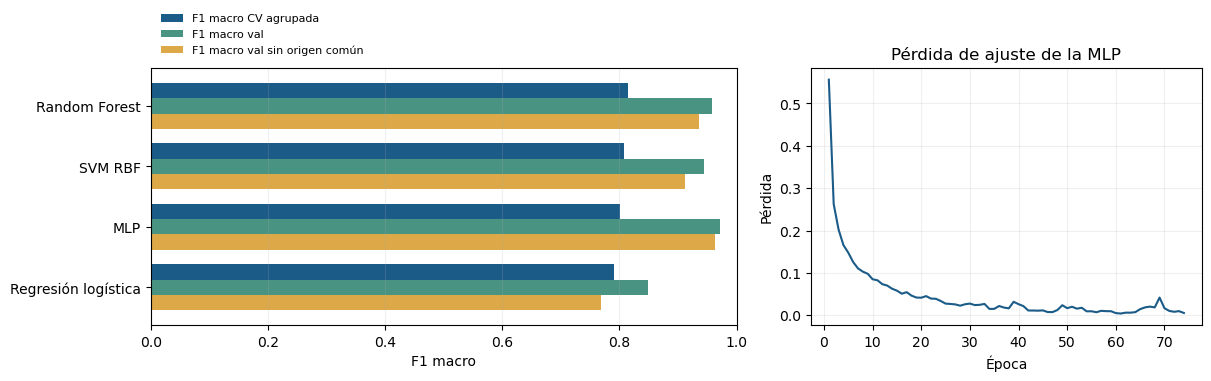

In [5]:
fig, (comparison, loss_plot) = plt.subplots(
    1, 2, figsize=(12, 3.7), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]}
)
comparison_cols = ["F1 macro CV agrupada", "F1 macro val", "F1 macro val sin origen común"]
summary[comparison_cols].plot.barh(
    ax=comparison, color=["#1b5b88", "#499383", "#dca848"], width=0.76,
)
comparison.invert_yaxis()
comparison.set(xlim=(0, 1), xlabel="F1 macro", ylabel="")
comparison.legend(loc="lower left", bbox_to_anchor=(0, 1.01), frameon=False, fontsize=8)
comparison.grid(axis="x", alpha=0.2)
loss_plot.plot(range(1, mlp.n_iter_ + 1), mlp.loss_curve_, color="#1b5b88")
loss_plot.set(title="Pérdida de ajuste de la MLP", xlabel="Época", ylabel="Pérdida")
loss_plot.grid(alpha=0.2)
plt.show()

### Interpretación de la ejecución guardada

Random Forest obtuvo el F1 macro más alto de los folds agrupados (0,8140), seguido de cerca por SVM RBF (0,8085). La diferencia de 0,0055 es menor que la variación observada entre folds. Random Forest queda como candidato para la Fase 5 según el criterio de selección.

La MLP lideró en la validación heredada (0,9724) y obtuvo 0,9630 en las 2.127 filas sin coincidencia de nombre de origen. Su F1 macro en los folds agrupados fue 0,8006. En fase 5, la prueba por capturas y con ejemplares anotados permitirá medir cuánto se mantiene el desempeño fuera de las sesiones de ajuste.

## Checkpoints

Cada archivo `.joblib` conserva el estimador seleccionado con su preprocesamiento. Para predecir se pasa un `DataFrame` con las columnas de `feature_names` en el orden registrado en el JSON. El campo `sklearn_version` identifica la versión que generó los archivos. El archivo de métricas registra las rejillas, las particiones y el candidato a evaluar en la fase 5. Las predicciones se verifican después de recargar cada checkpoint.

In [6]:
checkpoints_dir = ROOT / "experiments" / "checkpoints"
results_dir = ROOT / "experiments" / "results"
checkpoints_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
report_path = results_dir / "fase4_modelado_metricas.json"

report = {
    "source_dataset": DATA_FILE.as_posix(),
    "feature_names": FEATURES,
    "class_order": CLASSES,
    "mixed_label": "Etiqueta de origen para recortes de fotos de calidades mezcladas",
    "split_counts": pd.crosstab(data["split"], data["quality"]).to_dict(orient="index"),
    "cv": {
        "selection_metric": "f1_macro",
        "strategy": "StratifiedGroupKFold",
        "seed": cv_seed,
        "capture_gap_seconds": 30,
        "train_groups": int(groups.nunique()),
        "validation_counts_by_fold": fold_counts.to_dict(orient="records"),
    },
    "shared_val_sources": len(shared_sources),
    "val_rows_with_shared_source": int((~different_source).sum()),
    "recommended_model": winner,
    "mlp_epochs": int(mlp.n_iter_),
    "sklearn_version": sklearn.__version__,
    "models": metrics_by_model,
}

probe = X_val.groupby(y_val, sort=False).head(5)
with tempfile.TemporaryDirectory(prefix="fase4_", dir=checkpoints_dir) as staging:
    staging_dir = Path(staging)
    for name, search in searches.items():
        checkpoint_path = staging_dir / metrics_by_model[name]["checkpoint"]
        joblib.dump(search.best_estimator_, checkpoint_path, compress=3)
        loaded = joblib.load(checkpoint_path)
        np.testing.assert_array_equal(loaded.feature_names_in_, FEATURES)
        np.testing.assert_array_equal(loaded.predict(probe), search.predict(probe))
    staged_report = staging_dir / report_path.name
    staged_report.write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    for result in metrics_by_model.values():
        filename = result["checkpoint"]
        (staging_dir / filename).replace(checkpoints_dir / filename)
        print((checkpoints_dir / filename).relative_to(ROOT))
    staged_report.replace(report_path)
    print(report_path.relative_to(ROOT))

experiments\checkpoints\fase4_regresion_logistica.joblib
experiments\checkpoints\fase4_svm_rbf.joblib
experiments\checkpoints\fase4_random_forest.joblib
experiments\checkpoints\fase4_mlp.joblib
experiments\results\fase4_modelado_metricas.json
